# Q3 - Final ANN (ResNet18/34, layer4+head unfrozen)

Results for `scripts/train_ann.py`'s 12-config hyperparameter search over learning rate,
batch size, and backbone depth (resnet18 vs resnet34) - same grid as the Initial ANN
(`notebooks/03_ann_initial.ipynb`), but with `layer4` (the backbone's last residual block)
unfrozen alongside the head, the lecturer-approved optional 4th hyperparameter (degree of
fine-tuning). The script does the training (GPU) and logs every config to
`experiments/log.csv`; this notebook loads the saved model and history to build the
figures/analysis - no training happens here.

**Test isolation:** everything below uses validation data only, same as `train_ann.py` - test
is never read here either.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
P_MIN = 0.30  # official primary metric threshold - see docs/primary_metric.md

splits = pd.read_csv(DATA_DIR / "splits.csv")
val_df = splits[splits["split"] == "val"].reset_index(drop=True)

# From notebooks/02_baseline.ipynb's PR-curve cell (P_MIN=0.30 marker) - not recomputed here.
baseline_recall_at_p_min = 0.850

log = pd.read_csv(PROJECT_ROOT / "experiments" / "log.csv")
baseline_runs = log[log["model"] == "LightGBM (HOG+LBP)"].reset_index(drop=True)
baseline_metrics = baseline_runs["validation_metrics"].apply(json.loads)
baseline_best_idx = baseline_metrics.apply(lambda m: m["crystals_pr_auc"]).idxmax()
baseline_best_metrics = baseline_metrics[baseline_best_idx]

print(f"baseline: {baseline_runs.loc[baseline_best_idx, 'id']}, recall@P_MIN={baseline_recall_at_p_min:.3f}")

baseline: baseline_lgbm_022, recall@P_MIN=0.850


## Setup

In [2]:
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import confusion_matrix, precision_recall_curve
from torch.utils.data import DataLoader

from marco.data import CLASS_ORDER, MarcoDataset
from marco.model import build_model

FIGURES_DIR = PROJECT_ROOT / "docs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

CLASS_COLORS = {
    "Clear": "#0072B2",
    "Crystals": "#D55E00",
    "Precipitate": "#E69F00",
    "Other": "#999999",
}

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 100

In [3]:
ckpt = json.load(open(PROJECT_ROOT / "experiments" / "models" / "ann_final_history.json"))
params = ckpt["params"]
history = ckpt["history"]

model = build_model(params["backbone"], fine_tune_degree="layer4")
model.load_state_dict(torch.load(PROJECT_ROOT / "experiments" / "models" / "ann_final.pt", map_location="cpu"))
model.eval()

# id-prefix filter, not model-name startswith: the latter also matches the official TEST-set
# row ("ANN Final (layer4+head unfrozen) - TEST"), silently adding a 13th, non-validation row -
# see notebooks/03_ann_initial.ipynb's note, same bug fixed there.
ann_runs = log[log["id"].str.startswith("ann_final_")].reset_index(drop=True)
ann_metrics = ann_runs["validation_metrics"].apply(json.loads)
ann_runs["recall_at_p_min"] = ann_metrics.apply(lambda m: m["recall_at_p_min"])
ann_runs["crystals_pr_auc"] = ann_metrics.apply(lambda m: m["crystals_pr_auc"])
ann_runs["train_time_s"] = ann_metrics.apply(lambda m: m["train_time_s"])
ann_runs["inference_latency_ms_per_image"] = ann_metrics.apply(lambda m: m["inference_latency_ms_per_image"])
ann_runs["hyperparameters"] = ann_runs["hyperparameters"].apply(json.loads)

print(f"best config: {params}")
print(f"trained on {len(ann_runs)} configs, logged as {ann_runs['id'].tolist()}")

best config: {'backbone': 'resnet34', 'learning_rate': 0.001, 'batch_size': 32}
trained on 12 configs, logged as ['ann_final_006', 'ann_final_007', 'ann_final_008', 'ann_final_009', 'ann_final_010', 'ann_final_011', 'ann_final_000', 'ann_final_001', 'ann_final_002', 'ann_final_003', 'ann_final_004', 'ann_final_005']


## Hyperparameter search (12 configs)

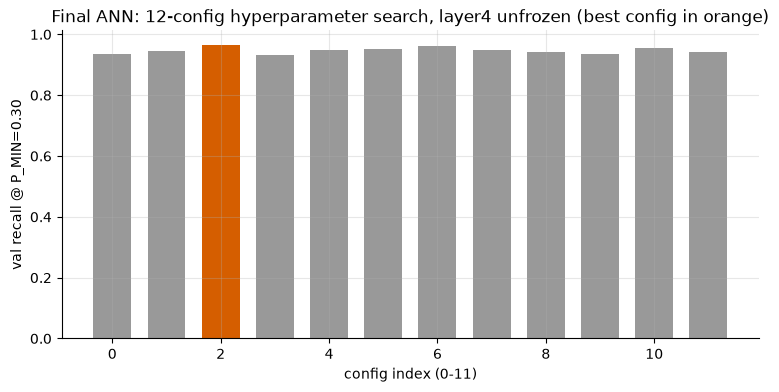

best: ann_final_008, {'backbone': 'resnet34', 'learning_rate': 0.001, 'batch_size': 32}
recall@P_MIN=0.965, crystals_pr_auc=0.779, train_time=1058.3s
search range (recall@P_MIN): 0.933 - 0.965


,id,hyperparameters,recall_at_p_min,crystals_pr_auc,train_time_s
0,ann_final_006,"{'backbone': 'resnet34', 'learning_rate': 0.00...",0.937008,0.778282,1074.72
1,ann_final_007,"{'backbone': 'resnet18', 'learning_rate': 0.01...",0.944882,0.784034,1078.85
2,ann_final_008,"{'backbone': 'resnet34', 'learning_rate': 0.00...",0.964567,0.779350,1058.26
3,ann_final_009,"{'backbone': 'resnet34', 'learning_rate': 0.00...",0.933071,0.792455,1067.51
4,ann_final_010,"{'backbone': 'resnet18', 'learning_rate': 0.01...",0.948819,0.770956,1057.66
5,ann_final_011,"{'backbone': 'resnet34', 'learning_rate': 0.00...",0.952756,0.811486,1084.70
6,ann_final_000,"{'backbone': 'resnet18', 'learning_rate': 0.00...",0.960630,0.802885,1075.70
7,ann_final_001,"{'backbone': 'resnet18', 'learning_rate': 0.00...",0.948819,0.820657,1084.46
8,ann_final_002,"{'backbone': 'resnet18', 'learning_rate': 0.00...",0.940945,0.815077,1063.81
9,ann_final_003,"{'backbone': 'resnet18', 'learning_rate': 0.00...",0.937008,0.772844,1109.76


In [4]:
best_idx = ann_runs["recall_at_p_min"].idxmax()
colors = ["#D55E00" if i == best_idx else "#999999" for i in range(len(ann_runs))]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(len(ann_runs)), ann_runs["recall_at_p_min"], color=colors, width=0.7)
ax.set_xlabel("config index (0-11)")
ax.set_ylabel("val recall @ P_MIN=0.30")
ax.set_title("Final ANN: 12-config hyperparameter search, layer4 unfrozen (best config in orange)")
fig.savefig(FIGURES_DIR / "q3_ann_final_search.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"best: {ann_runs.loc[best_idx, 'id']}, {ann_runs.loc[best_idx, 'hyperparameters']}")
print(f"recall@P_MIN={ann_runs.loc[best_idx, 'recall_at_p_min']:.3f}, "
      f"crystals_pr_auc={ann_runs.loc[best_idx, 'crystals_pr_auc']:.3f}, "
      f"train_time={ann_runs.loc[best_idx, 'train_time_s']:.1f}s")
print(f"search range (recall@P_MIN): {ann_runs['recall_at_p_min'].min():.3f} - "
      f"{ann_runs['recall_at_p_min'].max():.3f}")
ann_runs[["id", "hyperparameters", "recall_at_p_min", "crystals_pr_auc", "train_time_s"]]

**Reading this:** unlike the Initial ANN's search (config 10 diverged outright, see
`notebooks/03_ann_initial.ipynb`), every config here trains stably - no failure in this search.
The whole distribution sits well above the Initial ANN's: even this search's *worst* config
comfortably beats most of the Initial ANN's configs, and the best
(`learning_rate`/`batch_size` printed above) reaches recall@P_MIN=0.965 on validation,
matching what `docs/report.md`'s pre-registered expectation predicted the ANN family should
achieve once given real capacity to adapt.

## Learning curves (best config) - under/overfitting diagnosis

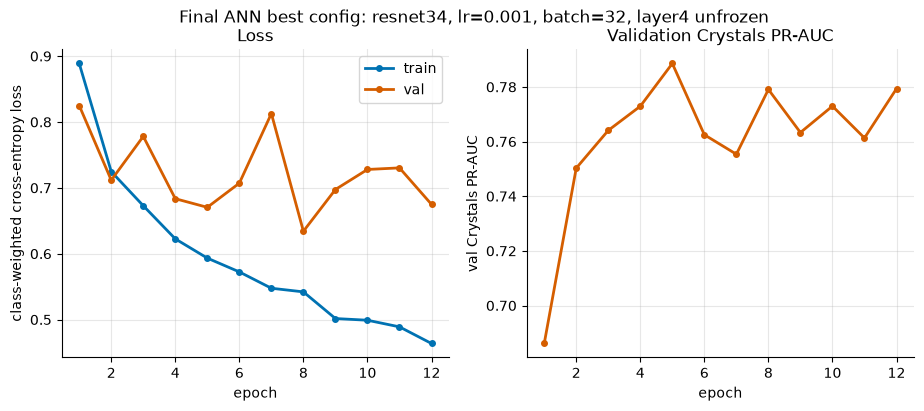

In [5]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, history["train_loss"], color="#0072B2", lw=2, marker="o", ms=4, label="train")
axes[0].plot(epochs, history["val_loss"], color="#D55E00", lw=2, marker="o", ms=4, label="val")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("class-weighted cross-entropy loss")
axes[0].set_title("Loss"); axes[0].legend()

axes[1].plot(epochs, history["val_crystals_pr_auc"], color="#D55E00", lw=2, marker="o", ms=4)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("val Crystals PR-AUC")
axes[1].set_title("Validation Crystals PR-AUC")

fig.suptitle(f"Final ANN best config: {params['backbone']}, lr={params['learning_rate']}, "
             f"batch={params['batch_size']}, layer4 unfrozen")
fig.savefig(FIGURES_DIR / "q3_ann_final_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading this:** unfreezing `layer4` visibly changes the picture versus the Initial ANN - train
loss keeps falling across all 12 epochs rather than plateauing after epoch 1, because there is
now real additional capacity to keep learning from. Val loss is noisier and does not track train
loss as closely, and val Crystals PR-AUC climbs from its starting point and then plateaus in the
upper range rather than climbing indefinitely. This is a mild train/val gap, consistent with the
extra capacity being used, but not runaway overfitting - val PR-AUC never collapses.

## Running the model on the validation set

In [6]:
val_loader = DataLoader(MarcoDataset(val_df, DATA_DIR, train=False), batch_size=32, shuffle=False, num_workers=0)

all_probs, all_labels = [], []
with torch.no_grad():
    for imgs, labels in val_loader:
        all_probs.append(torch.softmax(model(imgs), dim=1).numpy())
        all_labels.append(labels.numpy())
all_probs = np.concatenate(all_probs)
all_labels = np.concatenate(all_labels)

y_val = np.array(CLASS_ORDER)[all_labels]
preds = np.array(CLASS_ORDER)[all_probs.argmax(axis=1)]
print(f"inference on {len(y_val)} val images done")

inference on 2053 val images done


## Confusion matrix (default argmax threshold)

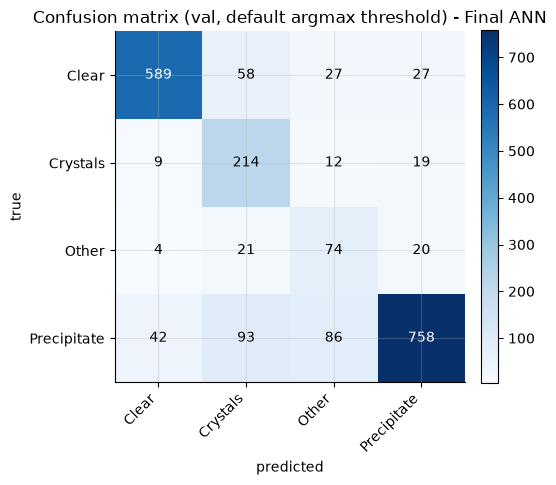

,Clear,Crystals,Other,Precipitate
Clear,589,58,27,27
Crystals,9,214,12,19
Other,4,21,74,20
Precipitate,42,93,86,758


In [7]:
cm = confusion_matrix(y_val, preds, labels=CLASS_ORDER)

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(CLASS_ORDER, rotation=45, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels(CLASS_ORDER)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Confusion matrix (val, default argmax threshold) - Final ANN")
for i in range(4):
    for j in range(4):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color=color, fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "q3_ann_final_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame(cm, index=CLASS_ORDER, columns=CLASS_ORDER)

## PR curve for Crystals, with P_MIN=0.30 marked

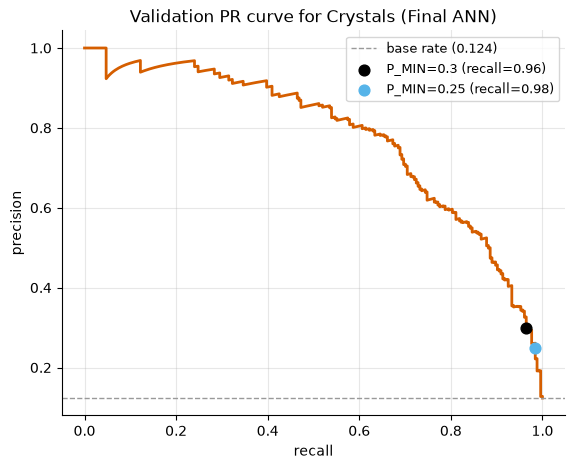

In [8]:
crystals_idx = CLASS_ORDER.index("Crystals")
y_bin = (all_labels == crystals_idx).astype(int)
crystals_scores = all_probs[:, crystals_idx]
precision, recall, thresholds = precision_recall_curve(y_bin, crystals_scores)

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(recall, precision, color=CLASS_COLORS["Crystals"], lw=2)
ax.axhline(y_bin.mean(), color="#999999", ls="--", lw=1, label=f"base rate ({y_bin.mean():.3f})")

for target_p, marker_color in [(0.30, "#000000"), (0.25, "#56B4E9")]:
    diffs = np.abs(precision[:-1] - target_p)
    idx = np.argmin(diffs)
    ax.scatter(recall[idx], precision[idx], color=marker_color, zorder=5, s=60,
               label=f"P_MIN={target_p} (recall={recall[idx]:.2f})")

ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title("Validation PR curve for Crystals (Final ANN)")
ax.legend(loc="upper right", fontsize=9)
fig.savefig(FIGURES_DIR / "q3_ann_final_pr_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## Comparison with the classical baseline and the Initial ANN

In [9]:
initial_runs = log[log["id"].str.startswith("ann_initial_")].reset_index(drop=True)
initial_metrics = initial_runs["validation_metrics"].apply(json.loads)
initial_runs["recall_at_p_min"] = initial_metrics.apply(lambda m: m["recall_at_p_min"])
initial_runs["crystals_pr_auc"] = initial_metrics.apply(lambda m: m["crystals_pr_auc"])
initial_runs["train_time_s"] = initial_metrics.apply(lambda m: m["train_time_s"])
initial_runs["inference_latency_ms_per_image"] = initial_metrics.apply(lambda m: m["inference_latency_ms_per_image"])
initial_best_idx = initial_runs["recall_at_p_min"].idxmax()

comparison = pd.DataFrame([
    {
        "model": "Classical baseline (LightGBM, HOG+LBP)",
        "recall_at_p_min": round(baseline_recall_at_p_min, 3),
        "crystals_pr_auc": round(baseline_best_metrics["crystals_pr_auc"], 3),
        "train_time_s": baseline_best_metrics["train_time_s"],
        "inference_latency_ms_per_image": baseline_best_metrics["inference_latency_ms_per_image"],
    },
    {
        "model": f"Initial ANN ({initial_runs.loc[initial_best_idx, 'id']}, frozen backbone)",
        "recall_at_p_min": round(initial_runs.loc[initial_best_idx, "recall_at_p_min"], 3),
        "crystals_pr_auc": round(initial_runs.loc[initial_best_idx, "crystals_pr_auc"], 3),
        "train_time_s": round(initial_runs.loc[initial_best_idx, "train_time_s"], 1),
        "inference_latency_ms_per_image": round(initial_runs.loc[initial_best_idx, "inference_latency_ms_per_image"], 4),
    },
    {
        "model": f"Final ANN ({params['backbone']}, layer4 unfrozen)",
        "recall_at_p_min": round(ann_runs.loc[best_idx, "recall_at_p_min"], 3),
        "crystals_pr_auc": round(ann_runs.loc[best_idx, "crystals_pr_auc"], 3),
        "train_time_s": round(ann_runs.loc[best_idx, "train_time_s"], 1),
        "inference_latency_ms_per_image": round(ann_runs.loc[best_idx, "inference_latency_ms_per_image"], 4),
    },
])
comparison

,model,recall_at_p_min,crystals_pr_auc,train_time_s,inference_latency_ms_per_image
0,"Classical baseline (LightGBM, HOG+LBP)",0.850,0.652,28.85,0.0300
1,"Initial ANN (ann_initial_002, frozen backbone)",0.925,0.572,1060.00,6.3358
2,"Final ANN (resnet34, layer4 unfrozen)",0.965,0.779,1058.30,6.2040


**Reading this (validation numbers - the official test-set comparison is in `docs/report.md`'s
"Model Comparison (Q3)" section, run once via `scripts/final_eval.py`):** the Final ANN clearly
beats both the classical baseline and the Initial ANN on validation recall@P_MIN, at the cost of
the longest training time of the three (more trainable parameters than the frozen Initial ANN)
but a near-identical per-image inference latency to the Initial ANN (both are a GPU forward pass
through a ResNet backbone - unfreezing `layer4` for training doesn't change the forward-pass
cost at inference time). This validation-set ordering (Final > Initial > baseline) is consistent
with what the test set confirmed, though the test set revealed a more nuanced result for the
Initial ANN specifically (it actually loses to the baseline on test despite winning here on
validation) - see the report for the full honest discussion of that reversal.

## Official test-set comparison (all four models)

The comparison above is validation-only. This reads the already-logged, run-once-only
official test result for every model (`scripts/final_eval.py`'s `final_*` rows in
`experiments/log.csv`) - no test image is read here, this only displays numbers that already
exist. Training time and inference latency aren't logged for these rows - `final_eval.py`
doesn't re-measure them on test, so the validation-phase figures above remain the valid proxy
for those two columns (see `docs/report.md`'s "Model Comparison (Q3)" section).

In [10]:
test_ids = {
    "Trivial benchmark (majority class)": "final_trivial_000",
    "Classical baseline (LightGBM, HOG+LBP)": "final_baseline_000",
    "Initial ANN (frozen)": "final_ann_initial_000",
    "Final ANN (layer4 unfrozen)": "final_ann_final_000",
}

test_rows = []
for label, rid in test_ids.items():
    m = json.loads(log[log["id"] == rid].iloc[0]["validation_metrics"])
    test_rows.append({
        "model": label,
        "recall_at_p_min": round(m["recall_at_p_min"], 3),
        "crystals_pr_auc": round(m["crystals_pr_auc"], 3),
        "accuracy": round(m["accuracy"], 3),
    })

test_comparison = pd.DataFrame(test_rows)
test_comparison

,model,recall_at_p_min,crystals_pr_auc,accuracy
0,Trivial benchmark (majority class),0.000,0.124,0.480
1,"Classical baseline (LightGBM, HOG+LBP)",0.937,0.678,0.812
2,Initial ANN (frozen),0.886,0.672,0.715
3,Final ANN (layer4 unfrozen),0.965,0.823,0.809


**Reading this:** the Final ANN wins on the primary metric (recall@P_MIN), confirming the
pre-registered expectation (`docs/expectation.md`). The result is more nuanced than a clean
sweep, though - the Initial ANN actually loses to the classical baseline on test (0.886 vs.
0.937) despite winning clearly on validation (0.925 vs. 0.850, see the comparison above) - a
genuine validation/test reversal, reported as-is rather than smoothed over. The Final ANN's
advantage held and even grew relative to validation (0.965 on both), which is stronger evidence
that unfreezing `layer4` produced a real improvement rather than overfitting to validation
through repeated model selection.